# PS- 5B: Intel Image Transfer Learning Using VGG16

This dataset has class labels, so this is image classification with transfer learning, not bounding-box detection.


In [9]:
# a. Import packages first
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG16


In [10]:
# b. Load updated Intel class folders and create train/validation datasets.
size = (128, 128)
train_ds = tf.keras.utils.image_dataset_from_directory(
    "Intel Image Classification", validation_split=0.2, subset="training",
    seed=42, image_size=size, batch_size=16
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    "Intel Image Classification", validation_split=0.2, subset="validation",
    seed=42, image_size=size, batch_size=16
)
val_ds = test_ds
class_names = train_ds.class_names


Found 12632 files belonging to 6 classes.
Using 10106 files for training.
Found 12632 files belonging to 6 classes.
Using 2526 files for validation.


In [11]:
# c and d. Load VGG16, freeze it, and add a small classifier.
base = VGG16(weights="vgg16_notop_weights.h5", include_top=False, input_shape=(128, 128, 3))
base.trainable = False
model = models.Sequential([
    layers.Rescaling(1./255),
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(len(class_names), activation="softmax")
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])


In [12]:
# e and f. Train and compute loss.
history = model.fit(train_ds.take(50), validation_data=val_ds.take(10), epochs=2)


Epoch 1/2
50/50 ━━━━━━━━━━━━━━━━━━━━ 73s 1s/step - accuracy: 0.3688 - loss: 1.6423 - val_accuracy: 0.5813 - val_loss: 1.4451
Epoch 2/2
50/50 ━━━━━━━━━━━━━━━━━━━━ 66s 1s/step - accuracy: 0.6463 - loss: 1.3127 - val_accuracy: 0.6375 - val_loss: 1.2162


In [13]:
# g. Evaluate loss and accuracy on test data.
loss, accuracy = model.evaluate(test_ds.take(10))
print("Loss:", loss)
print("Accuracy:", accuracy)


10/10 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.6625 - loss: 1.1968
Loss: 1.196829080581665
Accuracy: 0.6625000238418579


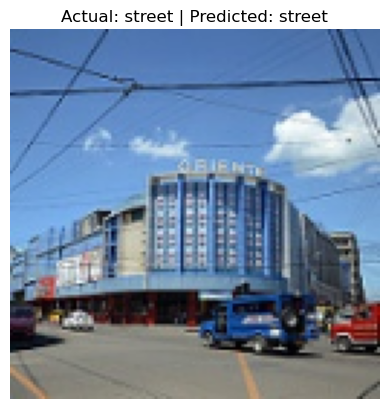

In [14]:
# h. Show one prediction.
for images, labels in test_ds.take(1):
    prediction = tf.argmax(model.predict(images[:1], verbose=0)[0]).numpy()
    plt.imshow(images[0].numpy().astype("uint8"))
    plt.title("Actual: " + class_names[labels[0]] + " | Predicted: " + class_names[prediction])
    plt.axis("off")
    plt.show()


In [15]:
# i. Fine tune the top VGG16 layers.
base.trainable = True
for layer in base.layers[:-4]:
    layer.trainable = False
model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.fit(train_ds.take(10), validation_data=val_ds.take(10), epochs=1)


10/10 ━━━━━━━━━━━━━━━━━━━━ 28s 2s/step - accuracy: 0.7063 - loss: 1.1013 - val_accuracy: 0.6500 - val_loss: 1.0355
